In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)

In [13]:
df = pd.read_csv('../data/raw/Customer-Churn-Records.csv')
print(df.shape)
df.head()

(10000, 18)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


In [14]:
df.info()
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  str    
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  str    
 5   Gender              10000 non-null  str    
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard           10000 non-null  int64  
 11  IsActiveMember      10000 non-null  int64  
 12  EstimatedSalary     10000 non-null  float64
 13  Exited              10000 non-null  int64  
 14  Complain            10000 non-null  int64  
 15  Satisfaction Score  10000 non-null  int64  
 16  Card Type       

In [15]:
df = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


In [16]:
for col in ['Geography', 'Gender', 'Card Type', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'Satisfaction Score']:
    print(col, ":", sorted(df[col].unique().tolist()))

Geography : ['France', 'Germany', 'Spain']
Gender : ['Female', 'Male']
Card Type : ['DIAMOND', 'GOLD', 'PLATINUM', 'SILVER']
NumOfProducts : [1, 2, 3, 4]
HasCrCard : [0, 1]
IsActiveMember : [0, 1]
Satisfaction Score : [1, 2, 3, 4, 5]


C:\Users\subha\AppData\Local\Temp\ipykernel_12632\4007268643.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Exited', data=df, palette='Set2')


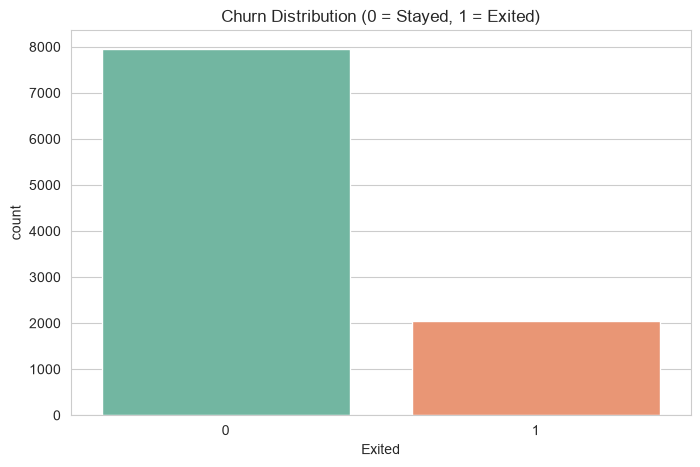

Exited
0    79.62
1    20.38
Name: proportion, dtype: float64


In [17]:
plt.figure()
sns.countplot(x='Exited', data=df, palette='Set2')
plt.title('Churn Distribution (0 = Stayed, 1 = Exited)')
plt.show()

print(df['Exited'].value_counts(normalize=True) * 100)

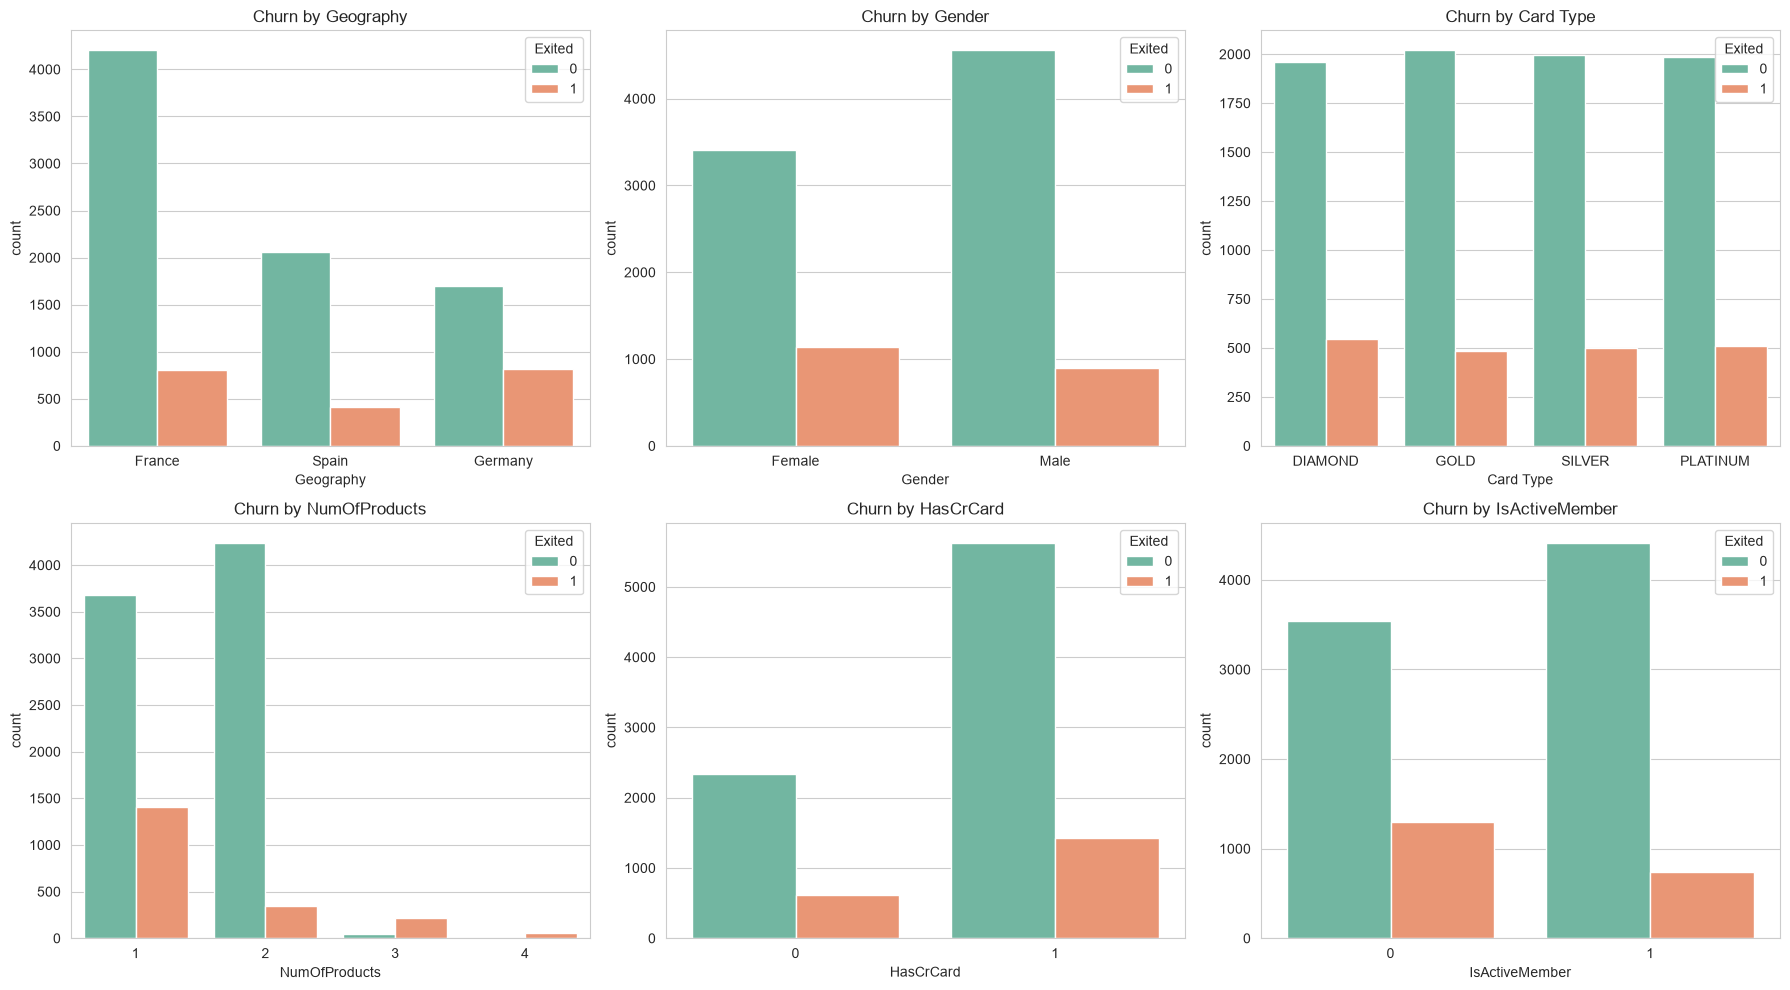

In [18]:
cat_cols = ['Geography', 'Gender', 'Card Type', 'NumOfProducts', 'HasCrCard', 'IsActiveMember']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, col in zip(axes.flatten(), cat_cols):
    sns.countplot(x=col, hue='Exited', data=df, ax=ax, palette='Set2')
    ax.set_title(f'Churn by {col}')
plt.tight_layout()
plt.show()

C:\Users\subha\AppData\Local\Temp\ipykernel_12632\4206363248.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Exited', y=col, data=df, ax=ax, palette='Set2')
C:\Users\subha\AppData\Local\Temp\ipykernel_12632\4206363248.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Exited', y=col, data=df, ax=ax, palette='Set2')
C:\Users\subha\AppData\Local\Temp\ipykernel_12632\4206363248.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Exited', y=col, data=df, ax=ax, palette='Set2')
C:\Users\subha\AppData\Local\Temp\ipykernel_12632\42063

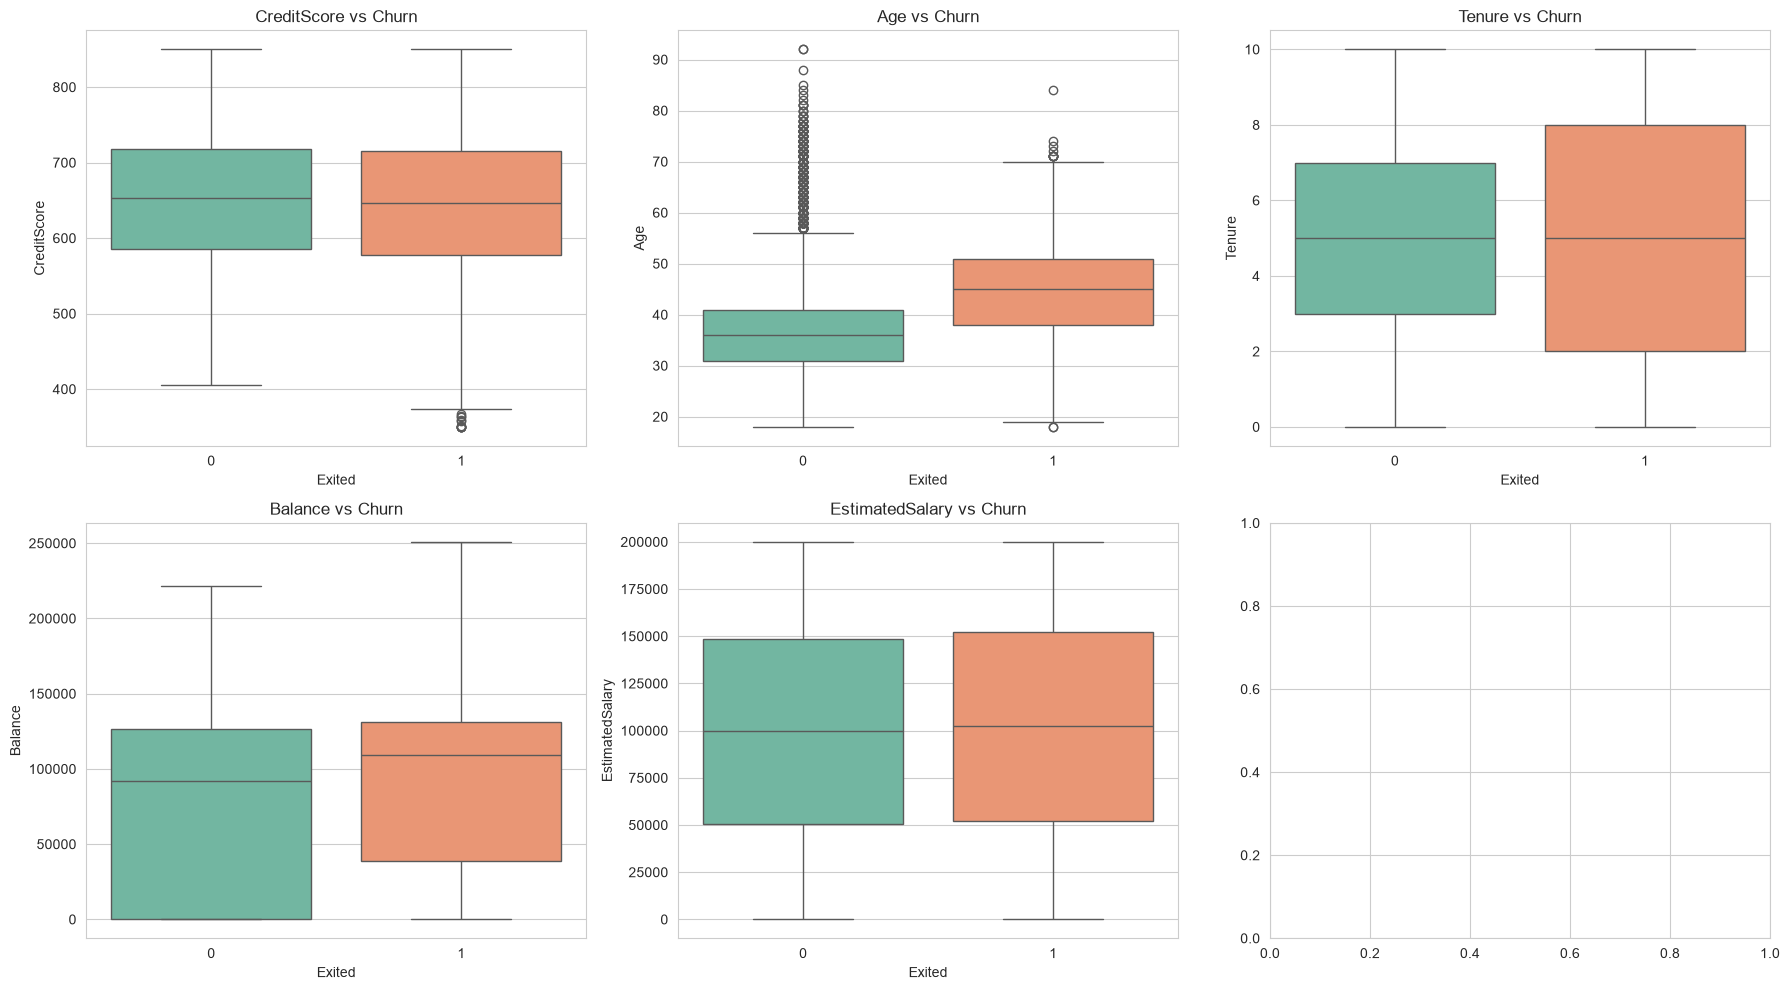

In [19]:
num_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'EstimatedSalary']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(x='Exited', y=col, data=df, ax=ax, palette='Set2')
    ax.set_title(f'{col} vs Churn')
plt.tight_layout()
plt.show()

In [20]:
pd.crosstab(df['Complain'], df['Exited'], normalize='index') * 100

Exited,0,1
Complain,,
0,99.949723,0.050277
1,0.489237,99.510763


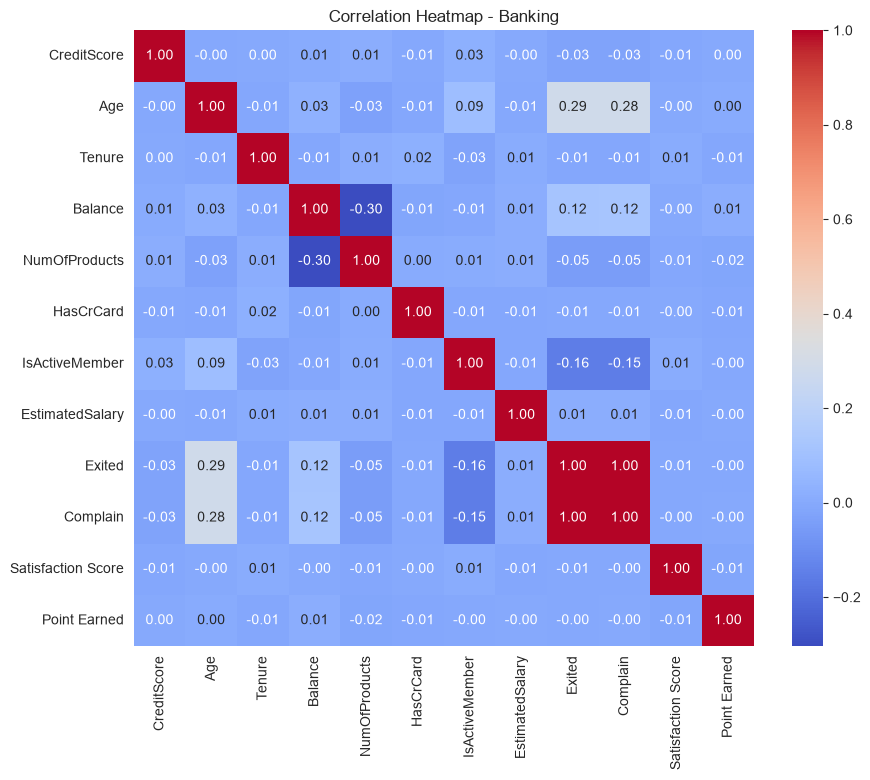

In [21]:
plt.figure(figsize=(10, 8))
corr = df.select_dtypes(include=[np.number]).corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap - Banking')
plt.show()

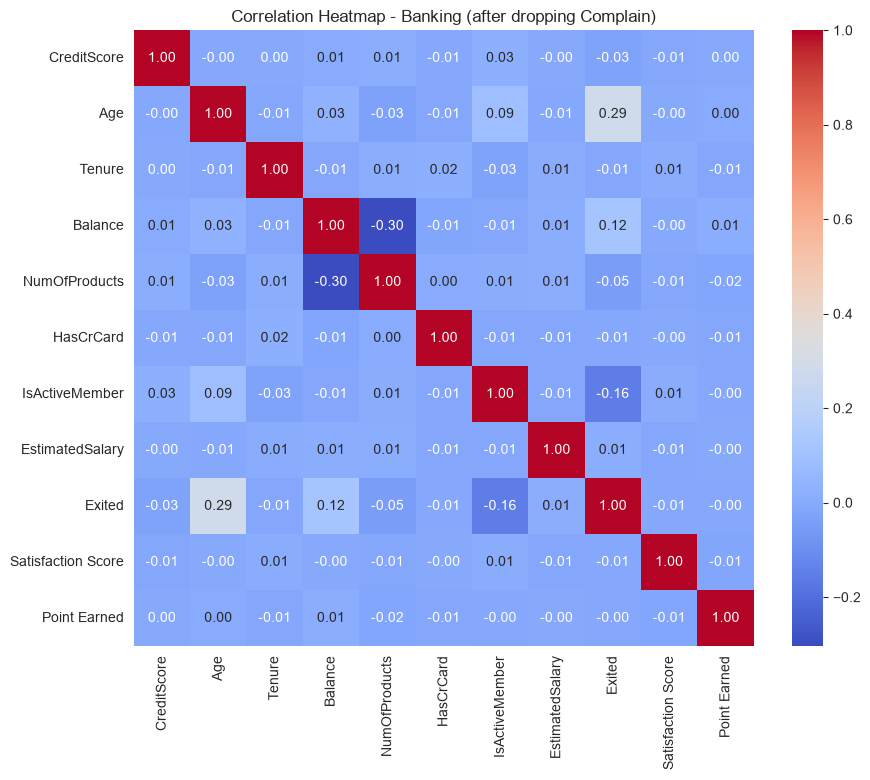

Train shape: (8000, 13) | Test shape: (2000, 13)
Decision Tree best params: {'max_depth': 6, 'min_samples_leaf': 2, 'min_samples_split': 5}
Random Forest best params: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}


In [ ]:
# ============================================================
# STEP 1: Drop leaking column, correlation heatmap
# ============================================================
df = df.drop(columns=['Complain'])

plt.figure(figsize=(10, 8))
corr = df.select_dtypes(include=[np.number]).corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap - Banking (after dropping Complain)')
plt.show()

# ============================================================
# STEP 2: Preprocessing
# ============================================================
from sklearn.model_selection import train_test_split, GridSearchCV, learning_curve
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                               f1_score, roc_auc_score, confusion_matrix,
                               ConfusionMatrixDisplay)
import joblib
import os

X = df.drop(columns=['Exited'])
y = df['Exited']

# Encode categorical columns
cat_cols = ['Geography', 'Gender', 'Card Type']
encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col])
    encoders[col] = le

# Train-test split (stratified to preserve churn ratio)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale (needed for SVM, doesn't hurt tree models)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)

# ============================================================
# STEP 3: Train models with GridSearchCV (prevents overfitting via CV)
# ============================================================
results = {}

# --- Decision Tree ---
dt_params = {'max_depth': [4, 6, 8, 10], 'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4]}
dt_grid = GridSearchCV(DecisionTreeClassifier(class_weight='balanced', random_state=42),
                        dt_params, cv=5, scoring='f1', n_jobs=-1)
dt_grid.fit(X_train_scaled, y_train)
results['Decision Tree'] = dt_grid.best_estimator_
print("Decision Tree best params:", dt_grid.best_params_)

# --- Random Forest ---
rf_params = {'n_estimators': [100, 200], 'max_depth': [6, 10, 15], 'min_samples_split': [2, 5]}
rf_grid = GridSearchCV(RandomForestClassifier(class_weight='balanced', random_state=42),
                        rf_params, cv=5, scoring='f1', n_jobs=-1)
rf_grid.fit(X_train_scaled, y_train)
results['Random Forest'] = rf_grid.best_estimator_
print("Random Forest best params:", rf_grid.best_params_)

# --- SVM ---
svm_params = {'C': [0.1, 1, 10], 'kernel': ['rbf', 'linear'], 'gamma': ['scale', 'auto']}
svm_grid = GridSearchCV(SVC(class_weight='balanced', probability=True, random_state=42),
                         svm_params, cv=5, scoring='f1', n_jobs=-1)
svm_grid.fit(X_train_scaled, y_train)
results['SVM'] = svm_grid.best_estimator_
print("SVM best params:", svm_grid.best_params_)

# ============================================================
# STEP 4: Check overfitting (train vs test accuracy gap)
# ============================================================
print("\n--- Overfitting Check ---")
for name, model in results.items():
    train_acc = accuracy_score(y_train, model.predict(X_train_scaled))
    test_acc = accuracy_score(y_test, model.predict(X_test_scaled))
    gap = train_acc - test_acc
    flag = "⚠️ possible overfitting" if gap > 0.10 else "✅ OK"
    print(f"{name}: Train={train_acc:.3f}, Test={test_acc:.3f}, Gap={gap:.3f} {flag}")

# ============================================================
# STEP 5: Full evaluation metrics
# ============================================================
print("\n--- Test Set Evaluation ---")
metrics_summary = []
for name, model in results.items():
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    metrics_summary.append([name, acc, prec, rec, f1, auc])
    print(f"\n{name}:")
    print(f"  Accuracy: {acc:.3f} | Precision: {prec:.3f} | Recall: {rec:.3f} | F1: {f1:.3f} | ROC-AUC: {auc:.3f}")

metrics_df = pd.DataFrame(metrics_summary, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC'])
print("\n", metrics_df)

# ============================================================
# STEP 6: Confusion matrices
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, model) in zip(axes, results.items()):
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

# ============================================================
# STEP 7: Model comparison bar chart
# ============================================================
metrics_df.set_index('Model')[['Accuracy', 'F1', 'ROC-AUC']].plot(kind='bar', figsize=(10, 6))
plt.title('Banking Domain: Model Comparison')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.show()

# ============================================================
# STEP 8: Save best model (highest F1) + scaler + encoders
# ============================================================
best_model_name = metrics_df.loc[metrics_df['F1'].idxmax(), 'Model']
best_model = results[best_model_name]
print(f"\n🏆 Best model: {best_model_name}")

os.makedirs('../models', exist_ok=True)
joblib.dump(best_model, '../models/banking_model.pkl')
joblib.dump(scaler, '../models/banking_scaler.pkl')
joblib.dump(encoders, '../models/banking_encoders.pkl')
print("Saved: banking_model.pkl, banking_scaler.pkl, banking_encoders.pkl")

In [ ]:
print(X.columns.tolist())

['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Satisfaction Score', 'Card Type', 'Point Earned']


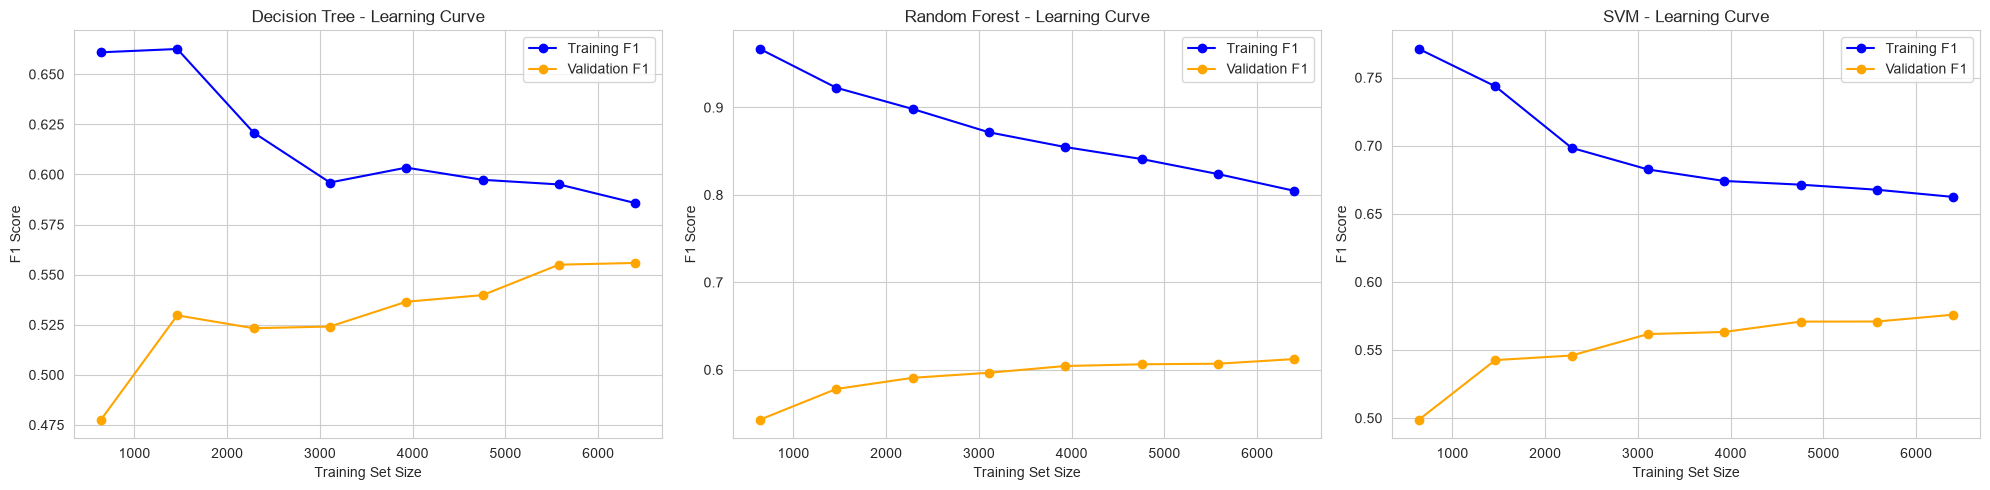


How to read this:
- If both lines are LOW and close together → UNDERFITTING (model too simple)
- If training line is HIGH but validation line is much LOWER (big gap) → OVERFITTING
- If both lines are HIGH and converge close together → GOOD FIT ✅



In [ ]:
# ============================================================
# LEARNING CURVES - Overfitting/Underfitting diagnostic
# ============================================================
from sklearn.model_selection import learning_curve

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for ax, (name, model) in zip(axes, results.items()):
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_train_scaled, y_train, cv=5, scoring='f1',
        train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1
    )
    train_mean = train_scores.mean(axis=1)
    val_mean = val_scores.mean(axis=1)

    ax.plot(train_sizes, train_mean, 'o-', label='Training F1', color='blue')
    ax.plot(train_sizes, val_mean, 'o-', label='Validation F1', color='orange')
    ax.set_title(f'{name} - Learning Curve')
    ax.set_xlabel('Training Set Size')
    ax.set_ylabel('F1 Score')
    ax.legend(loc='best')
    ax.grid(True)

plt.tight_layout()
plt.show()

print("""
How to read this:
- If both lines are LOW and close together → UNDERFITTING (model too simple)
- If training line is HIGH but validation line is much LOWER (big gap) → OVERFITTING
- If both lines are HIGH and converge close together → GOOD FIT ✅
""")